# Hybrid 02 · Leakage audit and donor-grouped evaluation

**Objective:** check that no feature encodes the grade, show why the earlier random splits were optimistic (fellow eyes of one donor in different partitions), and verify the donor-grouped 5 × 5 folds and grouped inner folds used from notebook 06 onward.

**Derived from:** `notebooks/images/06_leakage_audit_and_donor_folds.ipynb` (diagnostic), `scripts/modeling_setup.py`.
**Cohort:** K1, all 1,036 labelled tissues. **Runtime:** about 2 minutes.

Set up paths and load the 1,036 labelled tissues.

In [1]:
import re
import sys
import warnings
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

import cleaned_setup as cs
import modeling_setup as ms

warnings.filterwarnings("ignore", category=UserWarning)
labelled = ms.load_labelled_data()
X, y = labelled[ms.ALL_FEATURES], labelled[ms.TARGET]
print("Labelled tissues:", len(labelled), "| grades:", y.value_counts().to_dict())

Labelled tissues: 1036 | grades: {'A+': 545, 'A': 319, 'B': 172}


## 1. Does any feature encode the grade?

Search the free-text source columns for grade labels or suitability decisions; a feature parsed from such a column could carry the label.

In [2]:
label_pattern = re.compile(
    r"\b(grade|A\+|optical|tectonic|suitab\w*|unsuitab\w*|discard\w*|reject\w*|PK|DSAEK|DMEK|EK)\b",
    flags=re.IGNORECASE,
)
source_columns = ["Epithelium_Findings", "Stroma_Findings", "Descemet_Findings", "Endothelium_Findings"]
rows = []
for column in source_columns + ["Additional_Findings", "Konan_Comments"]:
    text = labelled[column].dropna().astype(str)
    rows.append({"Column": column, "Used for features": column in source_columns,
                 "Non-empty": len(text), "Label mentions": int(text.str.contains(label_pattern).sum())})
pd.DataFrame(rows)

,Column,Used for features,Non-empty,Label mentions
0,Epithelium_Findings,True,572,0
1,Stroma_Findings,True,573,0
2,Descemet_Findings,True,571,0
3,Endothelium_Findings,True,561,0
4,Additional_Findings,False,572,256
5,Konan_Comments,False,953,0


`Additional_Findings` contains release-form grades, so it is excluded. Confirm that no post-decision column is among the 24 features.

In [3]:
post_decision = {"Overall_Donor_Quality", "Transplant_Suitability", "Suitability_Reason", "Tissue_Outcome",
                 "Requested_Grade", "Grade_Request_Met", "Intended_Use", "Additional_Findings", "Review_Notes"}
print("Post-decision columns among the features:", sorted(post_decision & set(ms.ALL_FEATURES)) or "none")

Post-decision columns among the features: none


A feature that predicts the grade almost perfectly on its own would suggest leakage. Score each feature alone (Random Forest, 5-fold stratified CV).

In [4]:
def single_feature_pipeline(feature):
    return Pipeline([
        ("preprocessor", ms.make_preprocessor(
            numeric=[feature] if feature in ms.NUMERIC_FEATURES else [],
            binary=[feature] if feature in ms.CLINICAL_BINARY_FEATURES else [],
            categorical=[feature] if feature in ms.CLINICAL_CATEGORICAL_FEATURES else [],
        )),
        ("classifier", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                              random_state=ms.RANDOM_STATE, n_jobs=-1)),
    ])


single = pd.Series({
    f: cross_val_score(single_feature_pipeline(f), X[[f]], y, cv=ms.make_cv(), scoring="f1_macro").mean()
    for f in ms.ALL_FEATURES
}).sort_values(ascending=False)
single.head(8).round(3).to_frame("Macro F1 (feature alone)")

,Macro F1 (feature alone)
ECD_CD_cells_per_mm2,0.771
Total_Area_um2,0.572
SD,0.554
Total_Cell_Count,0.382
HEX_percent,0.366
CV,0.363
Epi_Has_Arcus,0.330
Epi_Has_Exposure,0.303


Missingness alone should not predict the grade, or models could learn from the absence of data.

In [5]:
missing_only = cross_val_score(
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=ms.RANDOM_STATE),
    X.isna().astype(int), y, cv=ms.make_cv(), scoring="f1_macro")
print(f"Macro F1 from missingness indicators only: {missing_only.mean():.3f} (chance ≈ 0.33)")

Macro F1 from missingness indicators only: 0.272 (chance ≈ 0.33)


## 2. Fellow eyes and inferred donors

No donor register was available. Fellow eyes receive consecutive serials, so `get_donor_groups` links consecutive opposite-eye tissues with the same donor age and cause or time of death.

In [6]:
cs.show_source(ms.get_donor_groups)

def get_donor_groups(df):
    """Infer a donor ID per tissue, aligned with df.index.

    Fellow eyes from one donor receive consecutive Tissue_Serial numbers
    with opposite eyes. Two consecutive tissues are treated as the same
    donor when they also share Donor_Age and either the cause of death
    or the death time, and their death times do not contradict each
    other. The rule errs towards grouping: merging two donors only costs
    fold balance, while missing a pair would leak a fellow eye.
    """
    d = df.sort_values("Tissue_Serial")
    prev = d.shift()

    cod = (
        d["Primary_COD"].astype(str).str.lower()
        .str.replace(r"[^a-z]", "", regex=True).str[:12]
    )
    death = d["Death_Date_Time"]
    both_death = death.notna() & prev["Death_Date_Time"].notna()
    same_death = both_death & (death == prev["Death_Date_Time"])

    same_donor = (
        (d["Tissue_Serial"].diff() == 1)
        & (d["Eye"] != prev["Eye"])
        & d["Donor_Age"].notna()
      

Infer donors and measure how often fellow eyes share a grade, compared with chance agreement.

In [7]:
labelled["Donor_Group"] = ms.get_donor_groups(labelled)
sizes = labelled["Donor_Group"].value_counts()
pairs = labelled[labelled["Donor_Group"].isin(sizes[sizes == 2].index)]
same_grade = pairs.groupby("Donor_Group")[ms.TARGET].agg(lambda g: g.iloc[0] == g.iloc[1]).mean()
chance = (y.value_counts(normalize=True) ** 2).sum()
print(f"Inferred donors: {labelled['Donor_Group'].nunique()} ({(sizes == 2).sum()} fellow-eye pairs, {(sizes == 1).sum()} single tissues)")
print(f"Fellow eyes with the same grade: {same_grade:.1%} (expected by chance: {chance:.1%})")

Inferred donors: 778 (258 fellow-eye pairs, 520 single tissues)
Fellow eyes with the same grade: 77.9% (expected by chance: 39.9%)


Donor details should agree within an inferred pair (aggregates only; no donor attributes are printed).

In [8]:
def pair_agreement(column):
    values = pairs.groupby("Donor_Group")[column].agg(list)
    both = values[values.map(lambda v: pd.notna(v[0]) and pd.notna(v[1]))]
    return pd.Series({"Pairs with both values": len(both), "Identical": both.map(lambda v: v[0] == v[1]).mean()})


pd.DataFrame({c: pair_agreement(c) for c in ["Donor_Age", "Primary_COD", "Death_Date_Time"]}).T.round(3)

,Pairs with both values,Identical
Donor_Age,258.0,1.00
Primary_COD,258.0,0.88
Death_Date_Time,208.0,1.00


## 3. The earlier splits separated fellow eyes

Count donor pairs whose two eyes fell into different partitions of the 80/20 tabular holdout (V0, notebook 05) and the 70/15/15 shared image split (V1, image notebooks 02–05).

In [9]:
def pairs_split_apart(split_df, id_column, id_map=None):
    ids = labelled["Tissue_ID"] if id_map is None else labelled["Tissue_ID"].map(id_map)
    assignment = ids.map(dict(zip(split_df[id_column], split_df["Split"])))
    per_donor = (pd.DataFrame({"donor": labelled["Donor_Group"], "split": assignment}).dropna()
                 .groupby("donor")["split"].agg(["size", "nunique"]))
    paired = per_donor[per_donor["size"] > 1]
    return int((paired["nunique"] > 1).sum()), len(paired)


for name, split_df, column, id_map in [
    ("V0: 80/20 tabular holdout", pd.read_csv(ms.SPLIT_PATH), "Tissue_ID", None),
    ("V1: 70/15/15 shared image split", pd.read_csv(cs.SHARED_SPLIT_PATH), "Normalized_ID", cs.normalize_id),
]:
    apart, total = pairs_split_apart(split_df, column, id_map)
    print(f"{name}: {apart} of {total} donor pairs split across partitions")

V0: 80/20 tabular holdout: 78 of 258 donor pairs split across partitions


V1: 70/15/15 shared image split: 108 of 239 donor pairs split across partitions


Effect on the estimate: the notebook 05 tabular Random Forest, 5 repeats × 5 folds, ignoring donors versus grouping them (≈1 min).

In [10]:
def notebook05_rf():
    return Pipeline([("preprocessor", ms.make_preprocessor()),
                     ("classifier", RandomForestClassifier(**cs.NB05_RF_PARAMS))])


scores = {"Stratified (ignores donors)": [], "Donor-grouped": []}
for repeat in range(ms.N_REPEATS):
    seed = ms.RANDOM_STATE + repeat
    scores["Stratified (ignores donors)"] += list(cross_val_score(
        notebook05_rf(), X, y, scoring="f1_macro", cv=StratifiedKFold(ms.N_SPLITS, shuffle=True, random_state=seed)))
    scores["Donor-grouped"] += list(cross_val_score(
        notebook05_rf(), X, y, groups=labelled["Donor_Group"], scoring="f1_macro", cv=ms.make_group_cv(random_state=seed)))
pd.DataFrame({k: {"Mean macro F1": np.mean(v), "SD": np.std(v), "Folds": len(v)} for k, v in scores.items()}).T.round(3)

,Mean macro F1,SD,Folds
Stratified (ignores donors),0.858,0.015,25.0
Donor-grouped,0.844,0.020,25.0


The 25 fold scores under each design (the two designs use different fold assignments, so the points are not paired).

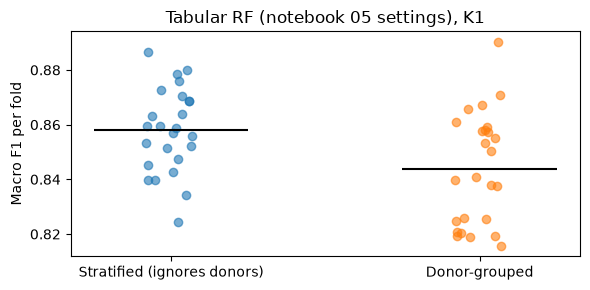

In [11]:
fig, ax = plt.subplots(figsize=(6, 3))
for i, (name, values) in enumerate(scores.items()):
    ax.scatter(np.full(len(values), i) + np.random.default_rng(0).uniform(-0.08, 0.08, len(values)), values, alpha=0.6)
    ax.hlines(np.mean(values), i - 0.25, i + 0.25, color="black")
ax.set(xticks=[0, 1], xticklabels=list(scores), ylabel="Macro F1 per fold", title="Tabular RF (notebook 05 settings), K1")
plt.tight_layout()
plt.show()

## 4. The donor-grouped folds used from notebook 06 onward (V2)

Load the saved fold file (never regenerated here) and check donor integrity: every donor sits in exactly one fold in every repeat.

In [12]:
folds = ms.get_donor_folds(labelled)
fold_columns = [f"Fold_r{r}" for r in range(ms.N_REPEATS)]
assert all((folds.groupby("Donor_Group")[c].nunique() == 1).all() for c in fold_columns)
assert (folds.set_index("Tissue_ID").loc[labelled["Tissue_ID"], "Donor_Group"].to_numpy() == labelled["Donor_Group"].to_numpy()).all()
print("Every donor is in a single fold in all 5 repeats; saved donor groups equal the inferred ones.")
check = folds.merge(labelled[["Tissue_ID", ms.TARGET]], on="Tissue_ID")
pd.crosstab(check["Fold_r0"], check[ms.TARGET])[cs.CLASSES].rename_axis("Fold (repeat 0)")

Every donor is in a single fold in all 5 repeats; saved donor groups equal the inferred ones.


Tissue_Grade_Clean,A+,A,B
Fold (repeat 0),,,
0,109,64,35
1,109,64,34
2,109,63,35
3,109,64,34
4,109,64,34


Regenerate the fold assignment in memory with the same splitter and seeds (42–46) and confirm it equals the saved file, so the folds are reproducible from code.

In [13]:
regenerated = {}
for repeat in range(ms.N_REPEATS):
    column = np.empty(len(labelled), dtype=int)
    splitter = StratifiedGroupKFold(n_splits=ms.N_SPLITS, shuffle=True, random_state=ms.RANDOM_STATE + repeat)
    for fold, (_, test_idx) in enumerate(splitter.split(labelled, y, groups=labelled["Donor_Group"])):
        column[test_idx] = fold
    regenerated[f"Fold_r{repeat}"] = column
saved = folds.set_index("Tissue_ID").loc[labelled["Tissue_ID"], fold_columns]
print("Regenerated folds equal the saved file:", all((saved[c].to_numpy() == regenerated[c]).all() for c in fold_columns))

Regenerated folds equal the saved file: True


Sub-cohorts reuse these folds by `Tissue_ID`: check one primary-cohort (K3) outer fold, and the 3-fold donor-grouped **inner** split used for tuning in notebooks 13–15.

In [14]:
k3, folds3, has_ecd = cs.primary_cohort()
X3, y3, donors3 = cs.feature_matrix(k3)
train, test = next(ms.iter_donor_folds(folds3, k3["Tissue_ID"], repeat=0))
assert set(donors3[train]).isdisjoint(donors3[test])
inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=ms.RANDOM_STATE)
for i, (tr, va) in enumerate(inner.split(train, y3[train], groups=donors3[train])):
    tr, va = train[tr], train[va]
    assert set(donors3[tr]).isdisjoint(donors3[va]) and set(y3[va]) == set(cs.CLASSES)
    print(f"Inner fold {i}: {len(tr)} train / {len(va)} validation tissues, no shared donors, all grades present")
print(f"Outer test fold: {len(test)} tissues ({has_ecd[test].sum()} with ECD), never used for tuning")

Inner fold 0: 298 train / 149 validation tissues, no shared donors, all grades present
Inner fold 1: 298 train / 149 validation tissues, no shared donors, all grades present
Inner fold 2: 298 train / 149 validation tissues, no shared donors, all grades present
Outer test fold: 104 tissues (86 with ECD), never used for tuning


Verify that preprocessing is fitted on training tissues only: after fitting the hybrid pipeline on one outer training fold, its imputer medians and embedding scaler means equal the training-fold statistics, not the whole-cohort ones.

In [15]:
pipe = cs.rf_pipeline(n_components=16).fit(X3.iloc[train], y3[train])
features = pipe.named_steps["features"]
medians = features.named_transformers_["tabular"].named_transformers_["numeric"].named_steps["imputer"].statistics_
scaler_mean = features.named_transformers_["image"].named_steps["scaler"].mean_
print("Imputer medians = training medians:", np.allclose(medians, X3.iloc[train][ms.NUMERIC_FEATURES].median()))
print("Imputer medians = whole-cohort medians:", np.allclose(medians, X3[ms.NUMERIC_FEATURES].median()))
print("Embedding scaler mean = training mean:", np.allclose(scaler_mean, X3.iloc[train][cs.EMBEDDING_COLUMNS].mean()))
print("Embedding scaler mean = whole-cohort mean:", np.allclose(scaler_mean, X3[cs.EMBEDDING_COLUMNS].mean()))

Imputer medians = training medians: True
Imputer medians = whole-cohort medians: False
Embedding scaler mean = training mean: True
Embedding scaler mean = whole-cohort mean: False


## Interpretation

- No feature encodes the grade: the best single feature is ECD (≈0.77 macro F1), slit-lamp features alone are near chance, and missingness alone is near chance.
- Fellow eyes share a grade about twice as often as chance, and 78 of 258 (V0) and 108 of 239 (V1) pairs were split across partitions, so earlier test sets contained near-duplicates of training tissues.
- Grouping by donor lowers the tabular estimate from 0.858 to 0.844 macro F1. Every result from notebook 06 onward uses the saved donor-grouped folds (V2), with grouped inner folds for tuning and all preprocessing inside the pipeline.

**Limitations:** donors are inferred from serial numbers and donor details, not confirmed against a register. The 0.858 → 0.844 comparison is diagnostic (no paired test; the designs use different folds). Missingness does not predict the grade, but it does identify the 2023 subset (Hybrid 03).